# Dry Bean Classification
Classify dry bean varieties(7 varieties)and compare five machine learning models and find best out of it.


## Student and Course Details

- **BITS ID:** 2026CT05143
- **Student Name:** Harish S
- **Assignment Number:** 2
- **Subject Code:** AMLCCZG565
- **Subject:** Machine Learning

### Imports


In [393]:
#Lib required imports 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report,
    roc_curve,
)
import time
RANDOM_STATE = 42
print("Imported")

Imported


### Loading the Dataset

In [394]:
#Loading the dataset
data = pd.read_csv("../Dry_Bean_Dataset.csv")
data

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13606,42097,759.696,288.721612,185.944705,1.552728,0.765002,42508,231.515799,0.714574,0.990331,0.916603,0.801865,0.006858,0.001749,0.642988,0.998385,DERMASON
13607,42101,757.499,281.576392,190.713136,1.476439,0.735702,42494,231.526798,0.799943,0.990752,0.922015,0.822252,0.006688,0.001886,0.676099,0.998219,DERMASON
13608,42139,759.321,281.539928,191.187979,1.472582,0.734065,42569,231.631261,0.729932,0.989899,0.918424,0.822730,0.006681,0.001888,0.676884,0.996767,DERMASON
13609,42147,763.779,283.382636,190.275731,1.489326,0.741055,42667,231.653247,0.705389,0.987813,0.907906,0.817457,0.006724,0.001852,0.668237,0.995222,DERMASON


### Dataset Overview

In [395]:
print("Total number of rows:", data.shape[0])
print("Total number of columns:", data.shape[1])
print("Input Features in the dataset:", data.columns[:-1].tolist())
print("Number of input features:", data.shape[1] - 1)
print("Target variable uniques:", np.unique(data['Class']))

Total number of rows: 13611
Total number of columns: 17
Input Features in the dataset: ['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4']
Number of input features: 16
Target variable uniques: ['BARBUNYA' 'BOMBAY' 'CALI' 'DERMASON' 'HOROZ' 'SEKER' 'SIRA']


In [396]:
data.head()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [397]:
data.tail()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
13606,42097,759.696,288.721612,185.944705,1.552728,0.765002,42508,231.515799,0.714574,0.990331,0.916603,0.801865,0.006858,0.001749,0.642988,0.998385,DERMASON
13607,42101,757.499,281.576392,190.713136,1.476439,0.735702,42494,231.526798,0.799943,0.990752,0.922015,0.822252,0.006688,0.001886,0.676099,0.998219,DERMASON
13608,42139,759.321,281.539928,191.187979,1.472582,0.734065,42569,231.631261,0.729932,0.989899,0.918424,0.822730,0.006681,0.001888,0.676884,0.996767,DERMASON
13609,42147,763.779,283.382636,190.275731,1.489326,0.741055,42667,231.653247,0.705389,0.987813,0.907906,0.817457,0.006724,0.001852,0.668237,0.995222,DERMASON
13610,42159,772.237,295.142741,182.204716,1.619841,0.786693,42600,231.686223,0.788962,0.989648,0.888380,0.784997,0.007001,0.001640,0.616221,0.998180,DERMASON


In [398]:
data.describe()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
count,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000
mean,53048.284549,855.283459,320.141867,202.270714,1.583242,0.750895,53768.200206,253.064220,0.749733,0.987143,0.873282,0.799864,0.006564,0.001716,0.643590,0.995063
std,29324.095717,214.289696,85.694186,44.970091,0.246678,0.092002,29774.915817,59.177120,0.049086,0.004660,0.059520,0.061713,0.001128,0.000596,0.098996,0.004366
min,20420.000000,524.736000,183.601165,122.512653,1.024868,0.218951,20684.000000,161.243764,0.555315,0.919246,0.489618,0.640577,0.002778,0.000564,0.410339,0.947687
25%,36328.000000,703.523500,253.303633,175.848170,1.432307,0.715928,36714.500000,215.068003,0.718634,0.985670,0.832096,0.762469,0.005900,0.001154,0.581359,0.993703
50%,44652.000000,794.941000,296.883367,192.431733,1.551124,0.764441,45178.000000,238.438026,0.759859,0.988283,0.883157,0.801277,0.006645,0.001694,0.642044,0.996386
75%,61332.000000,977.213000,376.495012,217.031741,1.707109,0.810466,62294.000000,279.446467,0.786851,0.990013,0.916869,0.834270,0.007271,0.002170,0.696006,0.997883
max,254616.000000,1985.370000,738.860154,460.198497,2.430306,0.911423,263261.000000,569.374358,0.866195,0.994677,0.990685,0.987303,0.010451,0.003665,0.974767,0.999733


In [399]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  str    
dtypes: float64(14), int64(2

In [400]:
data.shape

(13611, 17)

### Data Quality Checks


In [401]:
print(f"No of Duplicate Values : {data.duplicated().sum()}")
print(f"No of Missing Values : {data.isnull().sum().sum()}")
print(f"No of Nan Values : {data.isna().sum().sum()}")

No of Duplicate Values : 68
No of Missing Values : 0
No of Nan Values : 0


### Remove Duplicate Rows

In [402]:
df = data.drop_duplicates().reset_index(drop=True).copy()
print(f"No of Duplicate Values : {df.duplicated().sum()}")
df

No of Duplicate Values : 0


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13538,42097,759.696,288.721612,185.944705,1.552728,0.765002,42508,231.515799,0.714574,0.990331,0.916603,0.801865,0.006858,0.001749,0.642988,0.998385,DERMASON
13539,42101,757.499,281.576392,190.713136,1.476439,0.735702,42494,231.526798,0.799943,0.990752,0.922015,0.822252,0.006688,0.001886,0.676099,0.998219,DERMASON
13540,42139,759.321,281.539928,191.187979,1.472582,0.734065,42569,231.631261,0.729932,0.989899,0.918424,0.822730,0.006681,0.001888,0.676884,0.996767,DERMASON
13541,42147,763.779,283.382636,190.275731,1.489326,0.741055,42667,231.653247,0.705389,0.987813,0.907906,0.817457,0.006724,0.001852,0.668237,0.995222,DERMASON


In [403]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 13543 entries, 0 to 13542
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13543 non-null  int64  
 1   Perimeter        13543 non-null  float64
 2   MajorAxisLength  13543 non-null  float64
 3   MinorAxisLength  13543 non-null  float64
 4   AspectRation     13543 non-null  float64
 5   Eccentricity     13543 non-null  float64
 6   ConvexArea       13543 non-null  int64  
 7   EquivDiameter    13543 non-null  float64
 8   Extent           13543 non-null  float64
 9   Solidity         13543 non-null  float64
 10  roundness        13543 non-null  float64
 11  Compactness      13543 non-null  float64
 12  ShapeFactor1     13543 non-null  float64
 13  ShapeFactor2     13543 non-null  float64
 14  ShapeFactor3     13543 non-null  float64
 15  ShapeFactor4     13543 non-null  float64
 16  Class            13543 non-null  str    
dtypes: float64(14), int64(2

### Class Distribution

In [404]:
target_counts = df["Class"].value_counts()

print("Target Distribution - Bean Class")
print(target_counts.to_string())

Target Distribution - Bean Class
Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1860
CALI        1630
BARBUNYA    1322
BOMBAY       522


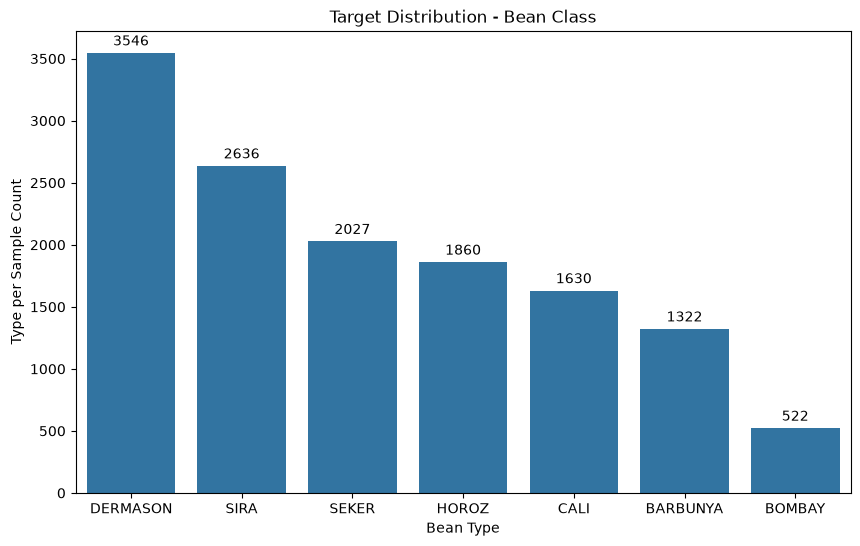

In [405]:
plt.figure(figsize=(10, 6))

ax = sns.countplot(
    data=df,
    x="Class",
    order=target_counts.index,
)
ax.bar_label(ax.containers[0], padding=3)
plt.title("Target Distribution - Bean Class")
plt.xlabel("Bean Type")
plt.ylabel("Type per Sample Count")
plt.show()

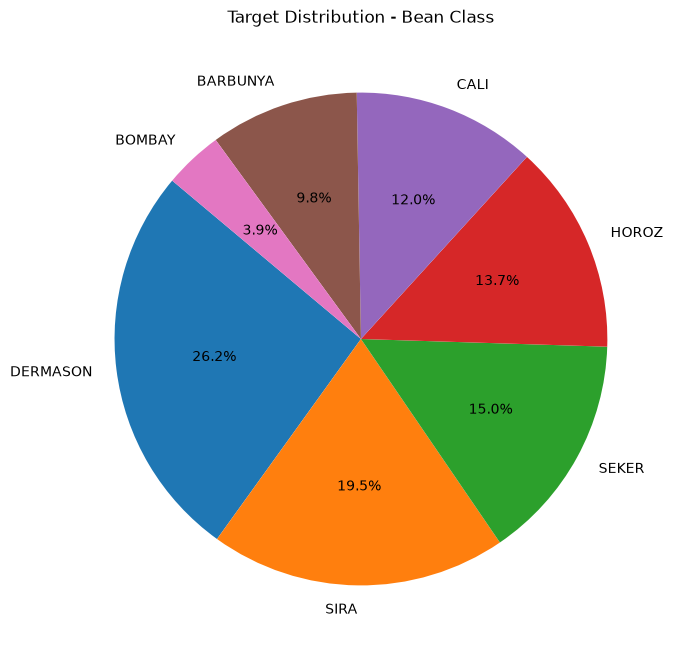

In [406]:
plt.figure(figsize=(8, 8))

plt.pie(
    target_counts,
    labels=target_counts.index,
    autopct='%1.1f%%',
    startangle=140
)

plt.title("Target Distribution - Bean Class")
plt.show()

### Features and Target

In [407]:
X = df.drop('Class', axis=1).copy()
y = df['Class'].copy()

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)

print(f"labeled classes : {label_encoder.classes_}, \nUnique Values: {np.unique(y)}")


labeled classes : ['BARBUNYA' 'BOMBAY' 'CALI' 'DERMASON' 'HOROZ' 'SEKER' 'SIRA'], 
Unique Values: [0 1 2 3 4 5 6]


### Train-Test Split

In [408]:
X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
    )


In [409]:
print("Training input features:", X_train.shape)
print("Testing input features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training input features: (10834, 16)
Testing input features: (2709, 16)
Training target: (10834,)
Testing target: (2709,)


### Verify Split dist and Class Balance in test and train

In [410]:
train_dist = pd.Series(y_train).value_counts(normalize=True).sort_index() * 100
test_dist = pd.Series(y_test).value_counts(normalize=True).sort_index() * 100

dist_comp = pd.DataFrame({
    "Training (%)": train_dist.values,
    "Testing (%)": test_dist.values
}, index=label_encoder.classes_)

print(dist_comp.round(2))

          Training (%)  Testing (%)
BARBUNYA          9.76         9.78
BOMBAY            3.86         3.84
CALI             12.04        12.03
DERMASON         26.19        26.17
HOROZ            13.73        13.73
SEKER            14.96        14.99
SIRA             19.47        19.45


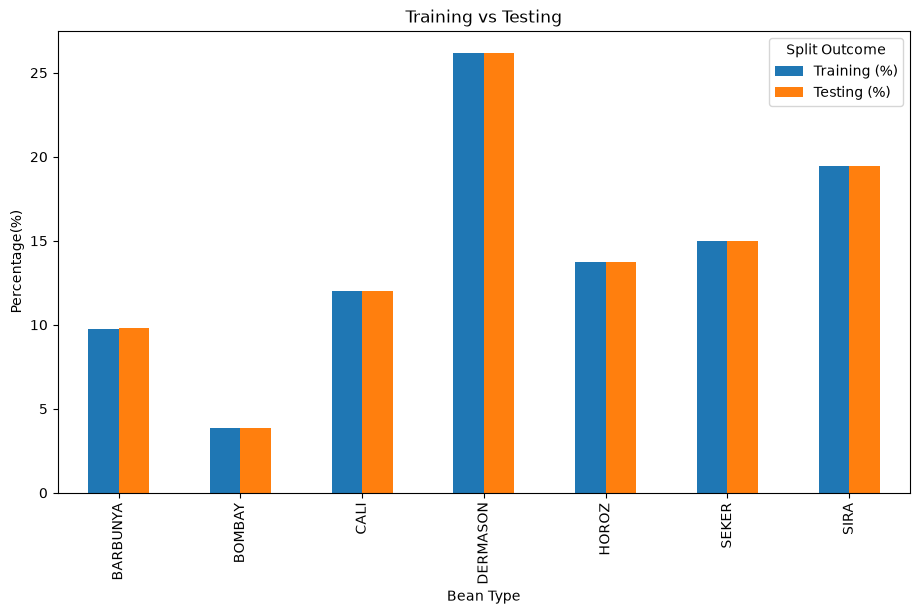

In [411]:
ax = dist_comp.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Training vs Testing")
plt.xlabel("Bean Type")
plt.ylabel("Percentage(%)")
plt.legend(title="Split Outcome")
plt.show()

### Missing-Value Imputation and Scaling

In [412]:
pipeline = Pipeline(steps=[
    ("imputer_Nan", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

X_train_scaled = pipeline.fit_transform(X_train)
X_test_scaled = pipeline.transform(X_test)
print(X_train_scaled[0:5])
print("Scaled Mean & Nan handled near zero:",np.round(X_train_scaled.mean(axis=0), 3))
print("Scaled SD & Nan handlednear one:",np.round(X_train_scaled.std(axis=0), 3))



[[ 0.56050943  1.00246171  0.92529133  0.50352511  0.78667132  0.82369554
   0.5822451   0.74988469 -0.87171546 -2.12216856 -1.87343212 -0.8981359
  -0.72427206 -1.05229514 -0.90313245 -2.30562193]
 [ 1.01720246  1.43581491  0.84032368  1.5209319  -0.54716576 -0.30038769
   1.02124725  1.21269015  1.56242482 -0.54152367 -1.74637446  0.46637367
  -1.62533534 -0.57423816  0.43516216 -0.15632666]
 [ 0.40962972  0.78736805  1.1598124  -0.07461418  2.1456669   1.41427087
   0.40306055  0.58730044  0.68843682  0.45224895 -1.58265048 -1.85362189
  -0.1039321  -1.40447613 -1.75538346 -0.49513515]
 [-0.39866175 -0.44628257 -0.37737953 -0.41904225 -0.05703053  0.21354366
  -0.4037397  -0.39831949  0.86345754  0.75459935  0.4656574  -0.04024022
   0.34974525  0.03292098 -0.07836033  0.5830616 ]
 [ 1.29692097  1.46408873  1.62760215  1.14608033  0.92897038  0.90335685
   1.27720601  1.47777335  0.804356    1.09385217 -0.60420684 -0.95902302
  -1.34656004 -1.30856174 -0.9595267  -0.17160759]]
Scale

### Exporting the Test Data

In [413]:
test_data = X_test.copy()
test_data["Class"] = y_test
test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns, index=X_test.index)
test_scaled["Class"] = y_test

test_data.to_csv("../test_data.csv", index=False)
test_scaled.to_csv("../test_scaled.csv", index=False)

### Evaluation Function
Calculate accuracy, multiclass AUC, precision, recall, F1, and MCC.

In [414]:
model_results = []
trained_models = {}

def evaluate_model(model_name, model, X_train, X_test, y_train, y_test):
    start_time = time.time()
    model.fit(X_train, y_train)
    training_time = time.time() - start_time

    y_pred = model.predict(X_test)

    y_prob = model.predict_proba(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    auc = roc_auc_score(
        y_test,
        y_prob,
        labels=model.classes_,
        multi_class="ovr",
        average="macro"
    )

    precision = precision_score(
        y_test, y_pred, average="macro", zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, average="macro", zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, average="macro", zero_division=0
    )

    mcc = matthews_corrcoef(y_test, y_pred)

    model_results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "AUC": auc,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "MCC": mcc,
        "Training Time (s)": training_time
    })

    trained_models[model_name] = model

    print(f"{model_name} - training Done!")
    print(f"Training time: {training_time:.4f} s")

    return y_pred, y_prob

### Logistic Regression

In [415]:
lr_model = LogisticRegression(
    random_state=RANDOM_STATE,
)

lr_pred, lr_prob = evaluate_model(
    "Logistic Regression",
    lr_model,
    X_train_scaled,
    X_test_scaled,
    y_train,
    y_test
)

Logistic Regression - training Done!
Training time: 0.3385 s


### Decision Tree

In [416]:
dt_model = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=None,
    min_samples_split=2,
    random_state=RANDOM_STATE
)

dt_pred, dt_prob = evaluate_model(
    "Decision Tree",
    dt_model,
    X_train_scaled,
    X_test_scaled,
    y_train,
    y_test
)

Decision Tree - training Done!
Training time: 0.4419 s


### K-Nearest Neighbors

In [417]:
knn_model = KNeighborsClassifier(
    n_neighbors=5,
    weights="uniform",
    metric="minkowski",
    p=2,
    n_jobs=-1
)

knn_pred, knn_prob = evaluate_model(
    "KNN Classifier",
    knn_model,
    X_train_scaled,
    X_test_scaled,
    y_train,
    y_test
)

KNN Classifier - training Done!
Training time: 0.0020 s


### Gaussian Naive Bayes

In [418]:
nb_model = GaussianNB()

nb_pred, nb_prob = evaluate_model(
    "Gaussian Naive Bayes",
    nb_model,
    X_train_scaled,
    X_test_scaled,
    y_train,
    y_test
)

Gaussian Naive Bayes - training Done!
Training time: 0.0100 s


### Random Forest Ensemble

In [419]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    criterion="entropy",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf_pred, rf_prob = evaluate_model(
    "Random Forest",
    rf_model,
    X_train_scaled,
    X_test_scaled,
    y_train,
    y_test
)

Random Forest - training Done!
Training time: 5.6574 s


### Model Results

In [420]:
results_df = pd.DataFrame(model_results)
display(results_df.round(4))

,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC,Training Time (s)
0,Logistic Regression,0.9195,0.9947,0.9311,0.9303,0.9306,0.9028,0.3385
1,Decision Tree,0.8885,0.9417,0.9001,0.9028,0.9013,0.8653,0.4419
2,KNN Classifier,0.9155,0.9832,0.9290,0.9256,0.9270,0.8978,0.0020
3,Gaussian Naive Bayes,0.8970,0.9911,0.9081,0.9082,0.9072,0.8762,0.0100
4,Random Forest,0.9173,0.9929,0.9305,0.9278,0.9290,0.9000,5.6574


### High Metric Scores

In [421]:
for metric in ["Accuracy", "F1 Score", "MCC","AUC", "Precision", "Recall"]:
    best = results_df.loc[results_df[metric].idxmax()]
    print(f"Highest {metric} Model: {best['Model']} ({best[metric]:.4f})\n")

Highest Accuracy Model: Logistic Regression (0.9195)

Highest F1 Score Model: Logistic Regression (0.9306)

Highest MCC Model: Logistic Regression (0.9028)

Highest AUC Model: Logistic Regression (0.9947)

Highest Precision Model: Logistic Regression (0.9311)

Highest Recall Model: Logistic Regression (0.9303)



### Confusion Matrices

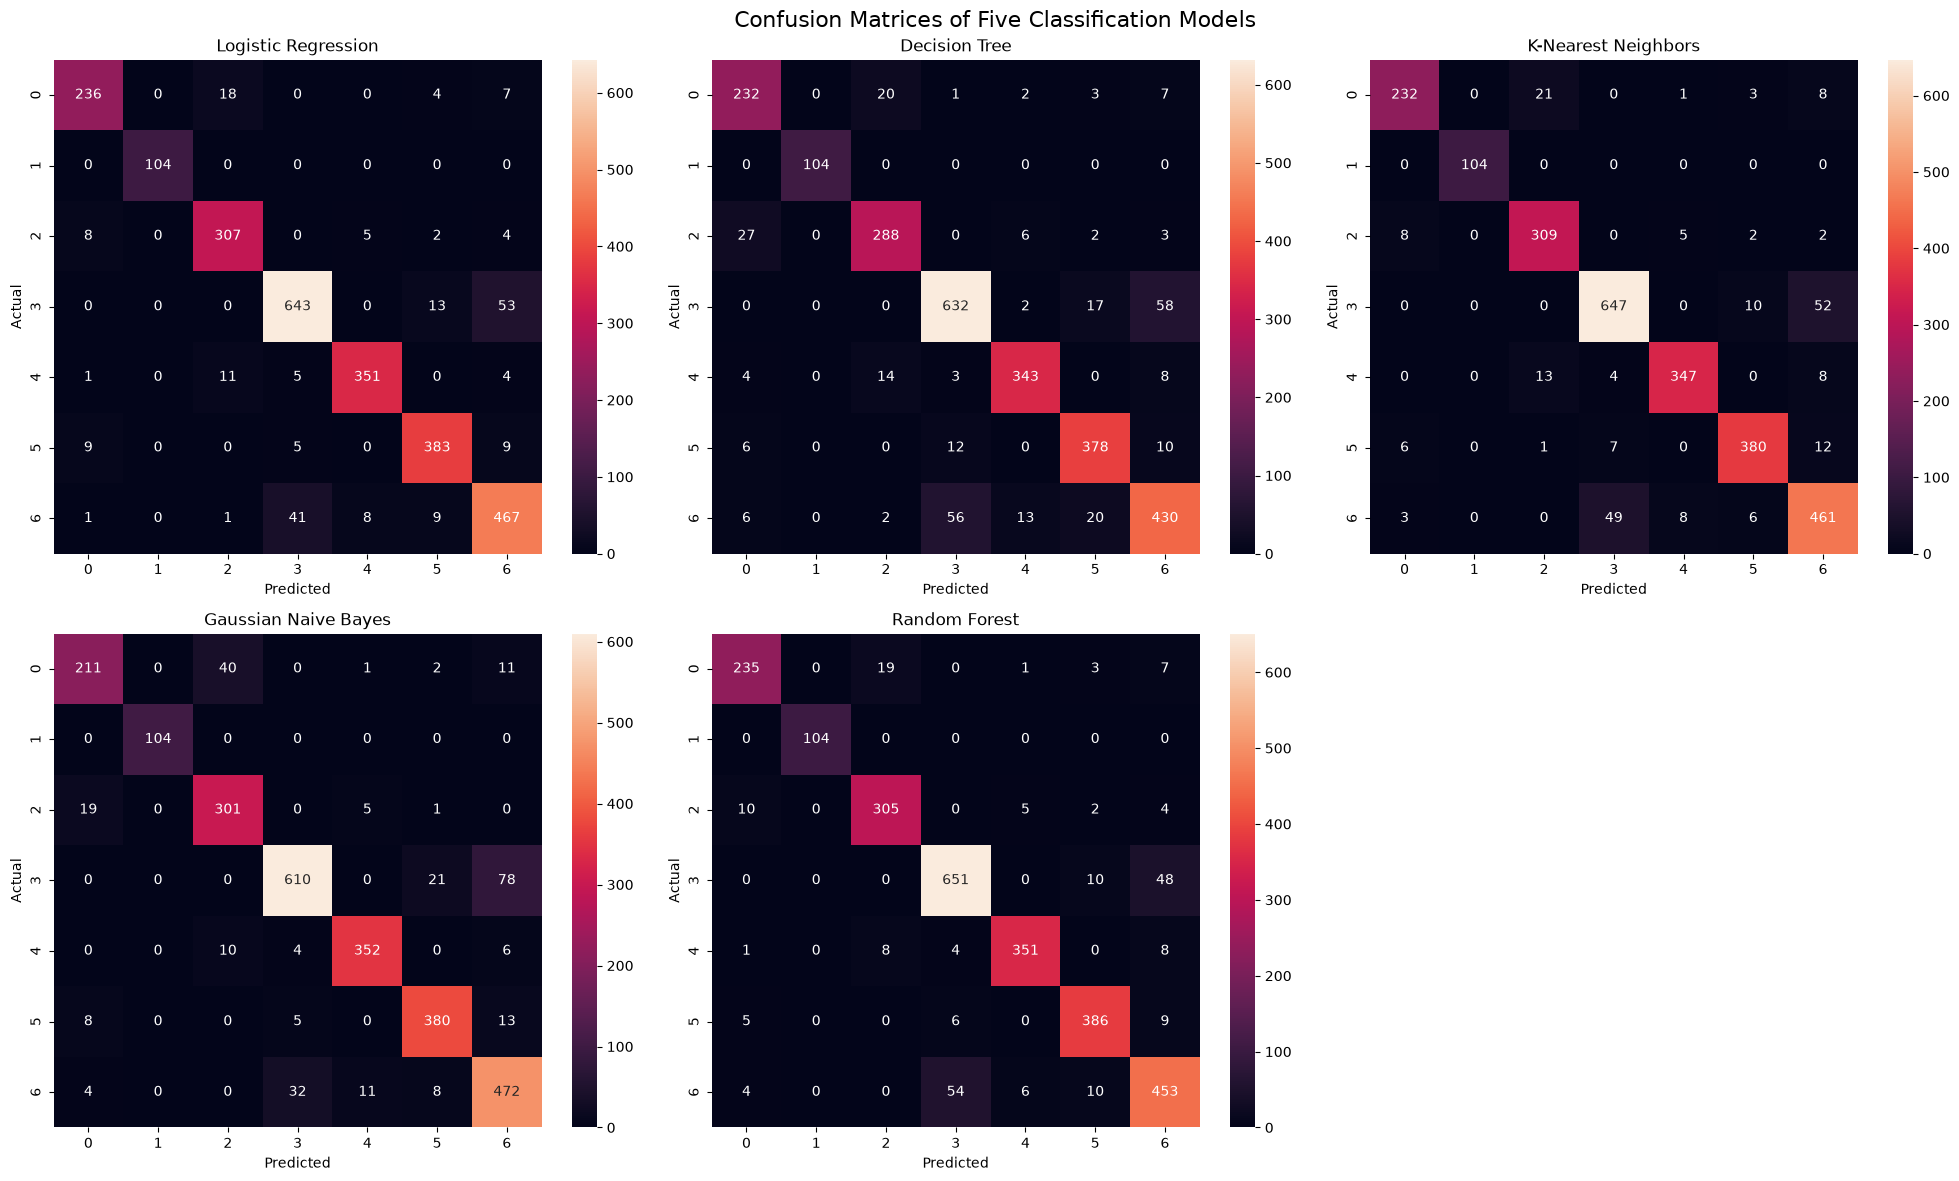

In [422]:
model_preds = {
    "Logistic Regression": lr_pred,
    "Decision Tree": dt_pred,
    "K-Nearest Neighbors": knn_pred,
    "Gaussian Naive Bayes": nb_pred,
    "Random Forest": rf_pred
}

labels = sorted(np.unique(y))
fig, axes = plt.subplots(2, 3, figsize=(20, 12))
axes = axes.flatten()

for index, (model_name, preds) in enumerate(model_preds.items()):

    cm = confusion_matrix(
        y_test,
        preds,
        labels=labels
    )

    sns.heatmap(
        cm,
        fmt="d",
        annot=True,
        xticklabels=labels,
        yticklabels=labels,
        ax=axes[index]
    )

    axes[index].set_title(model_name)
    axes[index].set_xlabel("Predicted")
    axes[index].set_ylabel("Actual")

fig.delaxes(axes[5])

plt.suptitle("Confusion Matrices of Five Classification Models", fontsize=16)
plt.tight_layout()
plt.show()


### Classification Reports

In [423]:
for model_name, preds in model_preds.items():
    print("\n" + "=" * 65)
    print(model_name)
    print("=" * 65)

    print(
        classification_report(
            y_test,
            preds,
            labels=labels,
            zero_division=0
        )
    )




Logistic Regression
              precision    recall  f1-score   support

           0       0.93      0.89      0.91       265
           1       1.00      1.00      1.00       104
           2       0.91      0.94      0.93       326
           3       0.93      0.91      0.92       709
           4       0.96      0.94      0.95       372
           5       0.93      0.94      0.94       406
           6       0.86      0.89      0.87       527

    accuracy                           0.92      2709
   macro avg       0.93      0.93      0.93      2709
weighted avg       0.92      0.92      0.92      2709


Decision Tree
              precision    recall  f1-score   support

           0       0.84      0.88      0.86       265
           1       1.00      1.00      1.00       104
           2       0.89      0.88      0.89       326
           3       0.90      0.89      0.89       709
           4       0.94      0.92      0.93       372
           5       0.90      0.93      0.9

### Metric Visualizations

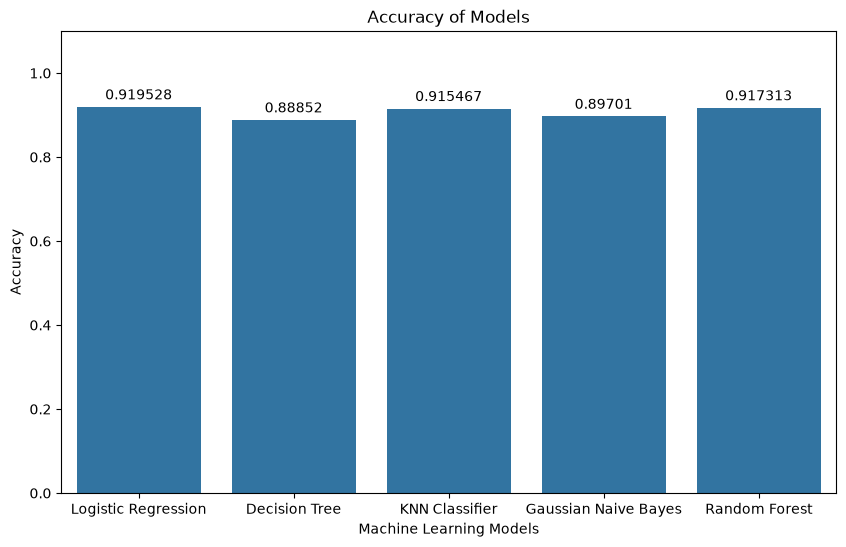

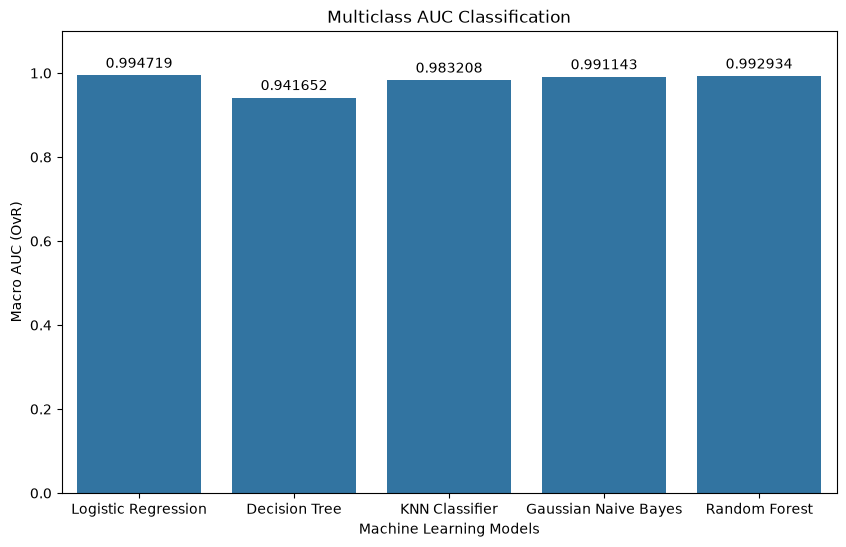

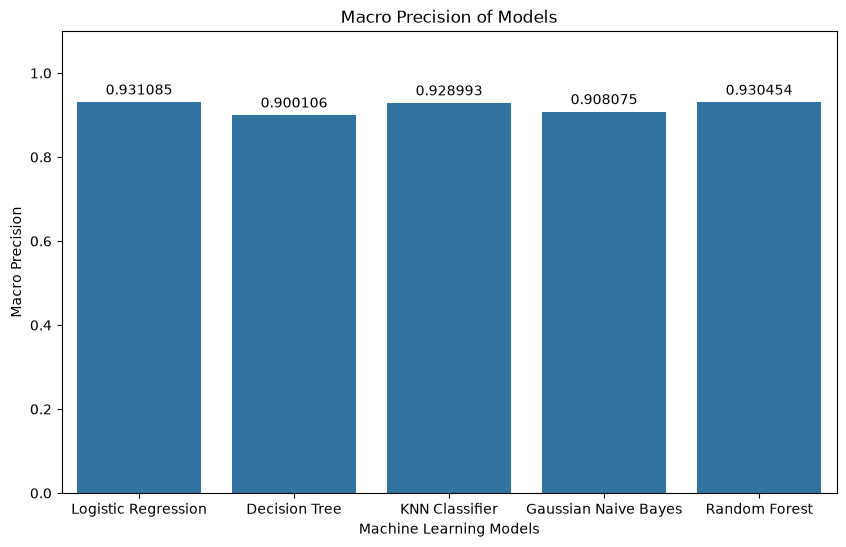

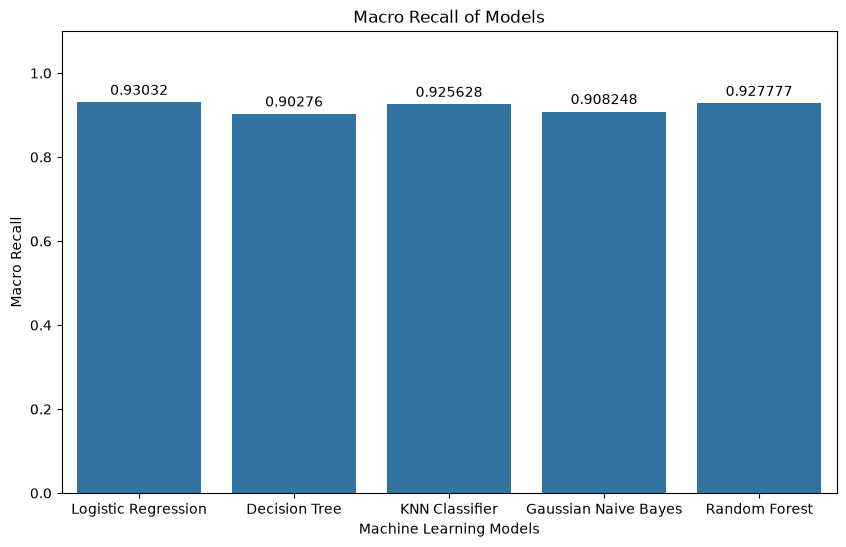

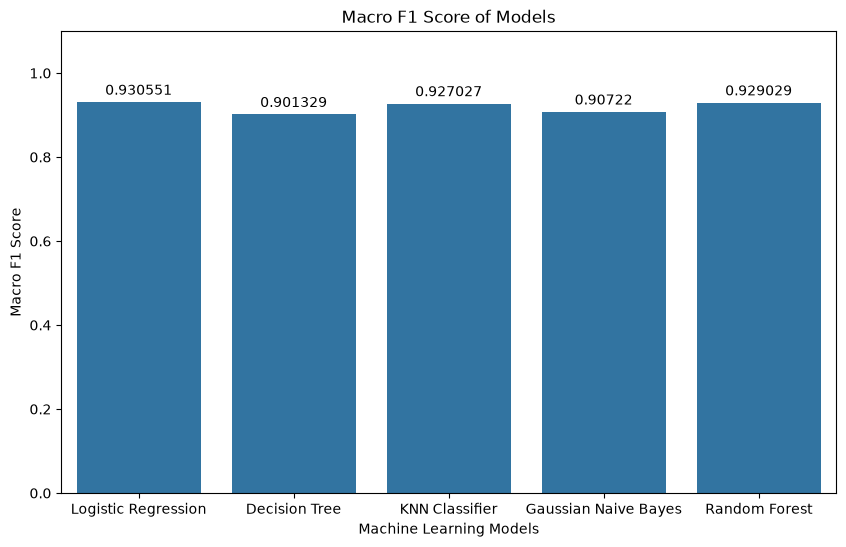

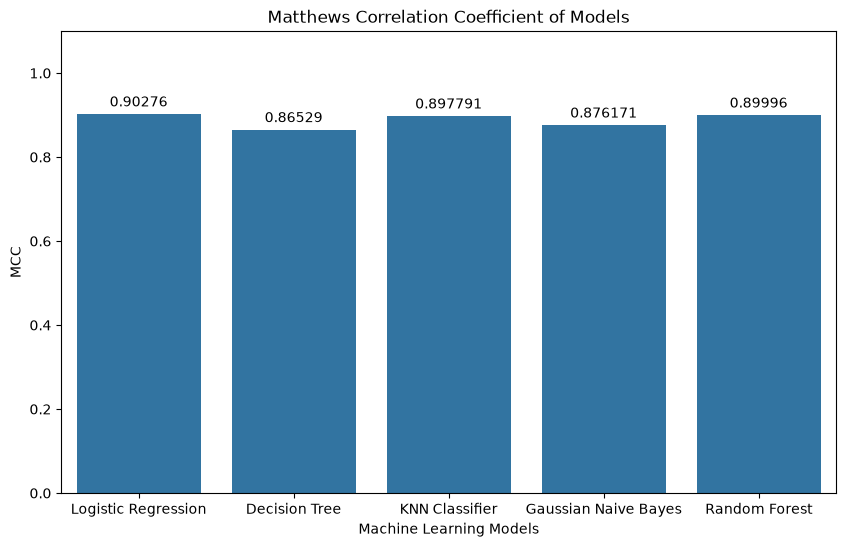

In [424]:
metrics_config = [
    ("Accuracy", "Accuracy of Models", "Accuracy"),
    ("AUC", "Multiclass AUC Classification", "Macro AUC (OvR)"),
    ("Precision", "Macro Precision of Models", "Macro Precision"),
    ("Recall", "Macro Recall of Models", "Macro Recall"),
    ("F1 Score", "Macro F1 Score of Models", "Macro F1 Score"),
    ("MCC", "Matthews Correlation Coefficient of Models", "MCC"),
]

for col, title, ylabel in metrics_config:
    plt.figure(figsize=(10, 6))
    ax = sns.barplot(data=results_df, x="Model", y=col)
    ax.bar_label(ax.containers[0], padding=3)
    plt.title(title)
    plt.xlabel("Machine Learning Models")
    plt.ylabel(ylabel)
    plt.ylim((0, 1.1))
    plt.show()

### Observations and Conclusion


In [425]:
metric_columns = ["Accuracy", "AUC", "Precision", "Recall", "F1 Score", "MCC"]
rank_models = results_df.sort_values("F1 Score", ascending=False).reset_index(drop=True)
rank_models.index = rank_models.index + 1
rank_models.index.name = "Rank"
print(rank_models[["Model"] + metric_columns].round(4))

winner = rank_models.iloc[0]
print(f"\nOverall Best by Macro F1: {winner['Model']} ({winner['F1 Score']:.4f})")

                     Model  Accuracy     AUC  Precision  Recall  F1 Score  \
Rank                                                                        
1      Logistic Regression    0.9195  0.9947     0.9311  0.9303    0.9306   
2            Random Forest    0.9173  0.9929     0.9305  0.9278    0.9290   
3           KNN Classifier    0.9155  0.9832     0.9290  0.9256    0.9270   
4     Gaussian Naive Bayes    0.8970  0.9911     0.9081  0.9082    0.9072   
5            Decision Tree    0.8885  0.9417     0.9001  0.9028    0.9013   

         MCC  
Rank          
1     0.9028  
2     0.9000  
3     0.8978  
4     0.8762  
5     0.8653  

Overall Best by Macro F1: Logistic Regression (0.9306)
